# 02 — Time-series Diagnostics (PM2.5)

## Setup

In [1]:
from pathlib import Path
import sys
import pandas as pd
import numpy as np
from IPython.display import display, Image

ROOT = Path.cwd().resolve()
if ROOT.name == 'notebooks':
    ROOT = ROOT.parent
if not (ROOT / 'src' / 'config.py').exists():
    raise FileNotFoundError(f"Project root not found from {Path.cwd()}; open/run inside the project.")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from src.config import DATA_FILE, RESULTS_DIR, FIGURES_DIR, SEED, MODEL_GROUP
from src.preprocessing import load_raw, clean_target
from src.eda import exploratory_data_table, audit_tables, eda_figures
from src.timeseries import temporal_station_table, lead_lag_correlations, temporal_figures
print('Input:', DATA_FILE)
print('Project:', ROOT)


Input: C:\Users\DM PHONEIX\PycharmProjects\PythonProject\data\raw\combined_gee_pm25.csv
Project: C:\Users\DM PHONEIX\PycharmProjects\PythonProject


In [2]:
raw=load_raw()
clean,cleaning=clean_target(raw)
print("After target cleaning:",len(clean),"rows across",clean.id.nunique(),"stations")

After target cleaning: 40983 rows across 95 stations


## Timestamp regularity and daily sampling

In [3]:
diagnostics=temporal_station_table(clean)
display(diagnostics[["node_id","n_records","t_min","t_max","pct_missing_intervals","acf_lag1","acf_lag7","acf_lag24","adf_p","kpss_p","ljung_box_p","_longest_run_days"]].head(12))
print("Stations with at least 20 consecutive observed days:",int((diagnostics._longest_run_days>=20).sum()))

,node_id,n_records,t_min,t_max,pct_missing_intervals,acf_lag1,acf_lag7,acf_lag24,adf_p,kpss_p,ljung_box_p,_longest_run_days
0,0,727,2016-12-07,2022-03-12,62.174818,0.665059,0.190997,0.054972,NaN,NaN,NaN,19
1,1,447,2016-11-25,2025-09-04,86.057392,0.384812,0.091125,0.162765,NaN,NaN,NaN,16
2,10,346,2018-01-17,2025-09-24,87.678063,0.607872,0.279750,0.521885,NaN,NaN,NaN,11
3,100,442,2024-01-28,2026-02-09,40.591398,0.669920,0.104568,-0.103324,0.425829,0.082344,2.099413e-08,30
4,101,771,2016-12-02,2023-04-12,66.810159,0.690124,0.268411,0.107460,NaN,NaN,NaN,16
5,102,798,2016-12-02,2022-11-06,63.157895,0.831555,0.319132,0.105087,NaN,NaN,NaN,16
6,103,593,2023-05-05,2025-09-28,32.460137,0.799743,0.490814,0.325301,0.000473,0.100000,4.459035e-02,22
7,104,235,2023-09-20,2024-08-30,32.080925,0.786590,0.237703,-0.009985,NaN,NaN,NaN,19
8,105,149,2024-01-28,2024-08-30,31.018519,0.716232,-0.168189,0.041111,0.020009,0.100000,4.327364e-02,31
9,106,268,2024-12-29,2026-02-09,34.313725,0.528500,0.206510,-0.100969,0.987979,0.100000,4.053239e-01,24


Stations with at least 20 consecutive observed days: 42


## Interpretation of ACF, PACF, ADF, KPSS and Ljung–Box

In [4]:
display(diagnostics[["acf_lag1","acf_lag7","acf_lag24","adf_p","kpss_p","ljung_box_p","pct_missing_intervals"]].describe().round(3))

,acf_lag1,acf_lag7,acf_lag24,adf_p,kpss_p,ljung_box_p,pct_missing_intervals
count,85.000,83.000,81.000,42.000,42.000,42.000,95.000
mean,0.621,0.167,0.077,0.300,0.076,0.154,49.869
std,0.176,0.149,0.145,0.316,0.033,0.267,15.838
min,0.141,-0.269,-0.261,0.000,0.010,0.000,0.000
25%,0.540,0.087,-0.008,0.022,0.034,0.000,39.342
50%,0.663,0.159,0.054,0.220,0.100,0.011,48.780
75%,0.766,0.263,0.163,0.396,0.100,0.238,61.448
max,0.860,0.491,0.522,1.000,0.100,0.983,95.474


## Monthly target drift and gas missingness

In [5]:
monthly=clean.groupby(clean.date.dt.to_period("M")).pm25.agg(count="count",median="median",iqr=lambda s:s.quantile(.75)-s.quantile(.25),pct_gt_25=lambda s:100*(s>25).mean())
display(monthly.tail(15).round(2))

,count,median,iqr,pct_gt_25
date,,,,
2025-02,557,9.21,7.56,4.85
2025-03,478,6.00,5.20,2.09
2025-04,563,6.50,5.81,0.71
2025-05,858,7.65,4.94,0.82
2025-06,741,13.59,7.81,7.42
2025-07,922,9.15,5.38,0.22
2025-08,1009,11.71,8.69,5.55
2025-09,835,6.36,4.38,1.08
2025-10,545,9.00,5.81,2.94


## Lead–lag diagnostics

In [6]:
lags=lead_lag_correlations(clean,max_lag=7)
display(lags.pivot(index="variable",columns="lag_days",values="spearman_rho").round(2))

lag_days,-7,-6,-5,-4,-3,-2,-1,0,1,2,3,4,5,6,7
variable,,,,,,,,,,,,,,,
AOD,0.03,0.04,0.05,0.05,0.09,0.11,0.15,0.18,0.12,0.07,0.07,0.03,0.02,0.02,0.00
CO,0.05,0.06,0.07,0.06,0.06,0.04,0.04,0.04,0.05,0.05,0.07,0.06,0.03,0.03,0.03
NO2,0.07,0.06,0.09,0.09,0.10,0.11,0.13,0.25,0.24,0.18,0.15,0.13,0.12,0.12,0.11
O3,-0.05,-0.06,-0.07,-0.06,-0.06,-0.07,-0.10,-0.14,-0.14,-0.10,-0.07,-0.06,-0.07,-0.08,-0.06
temperature_celsius,0.05,0.06,0.06,0.06,0.08,0.08,0.09,0.06,0.06,0.04,0.04,0.03,0.04,0.04,0.03
wind_u,0.01,-0.01,-0.02,-0.03,-0.04,-0.05,-0.10,-0.16,-0.16,-0.14,-0.12,-0.07,-0.06,-0.04,-0.03
wind_v,-0.00,0.01,0.02,0.03,0.04,0.04,0.06,0.10,0.07,0.02,-0.00,-0.01,0.01,0.01,-0.01


## Export outputs and charts

Saved C:\Users\DM PHONEIX\PycharmProjects\PythonProject\results\Exploratory_temporal.csv


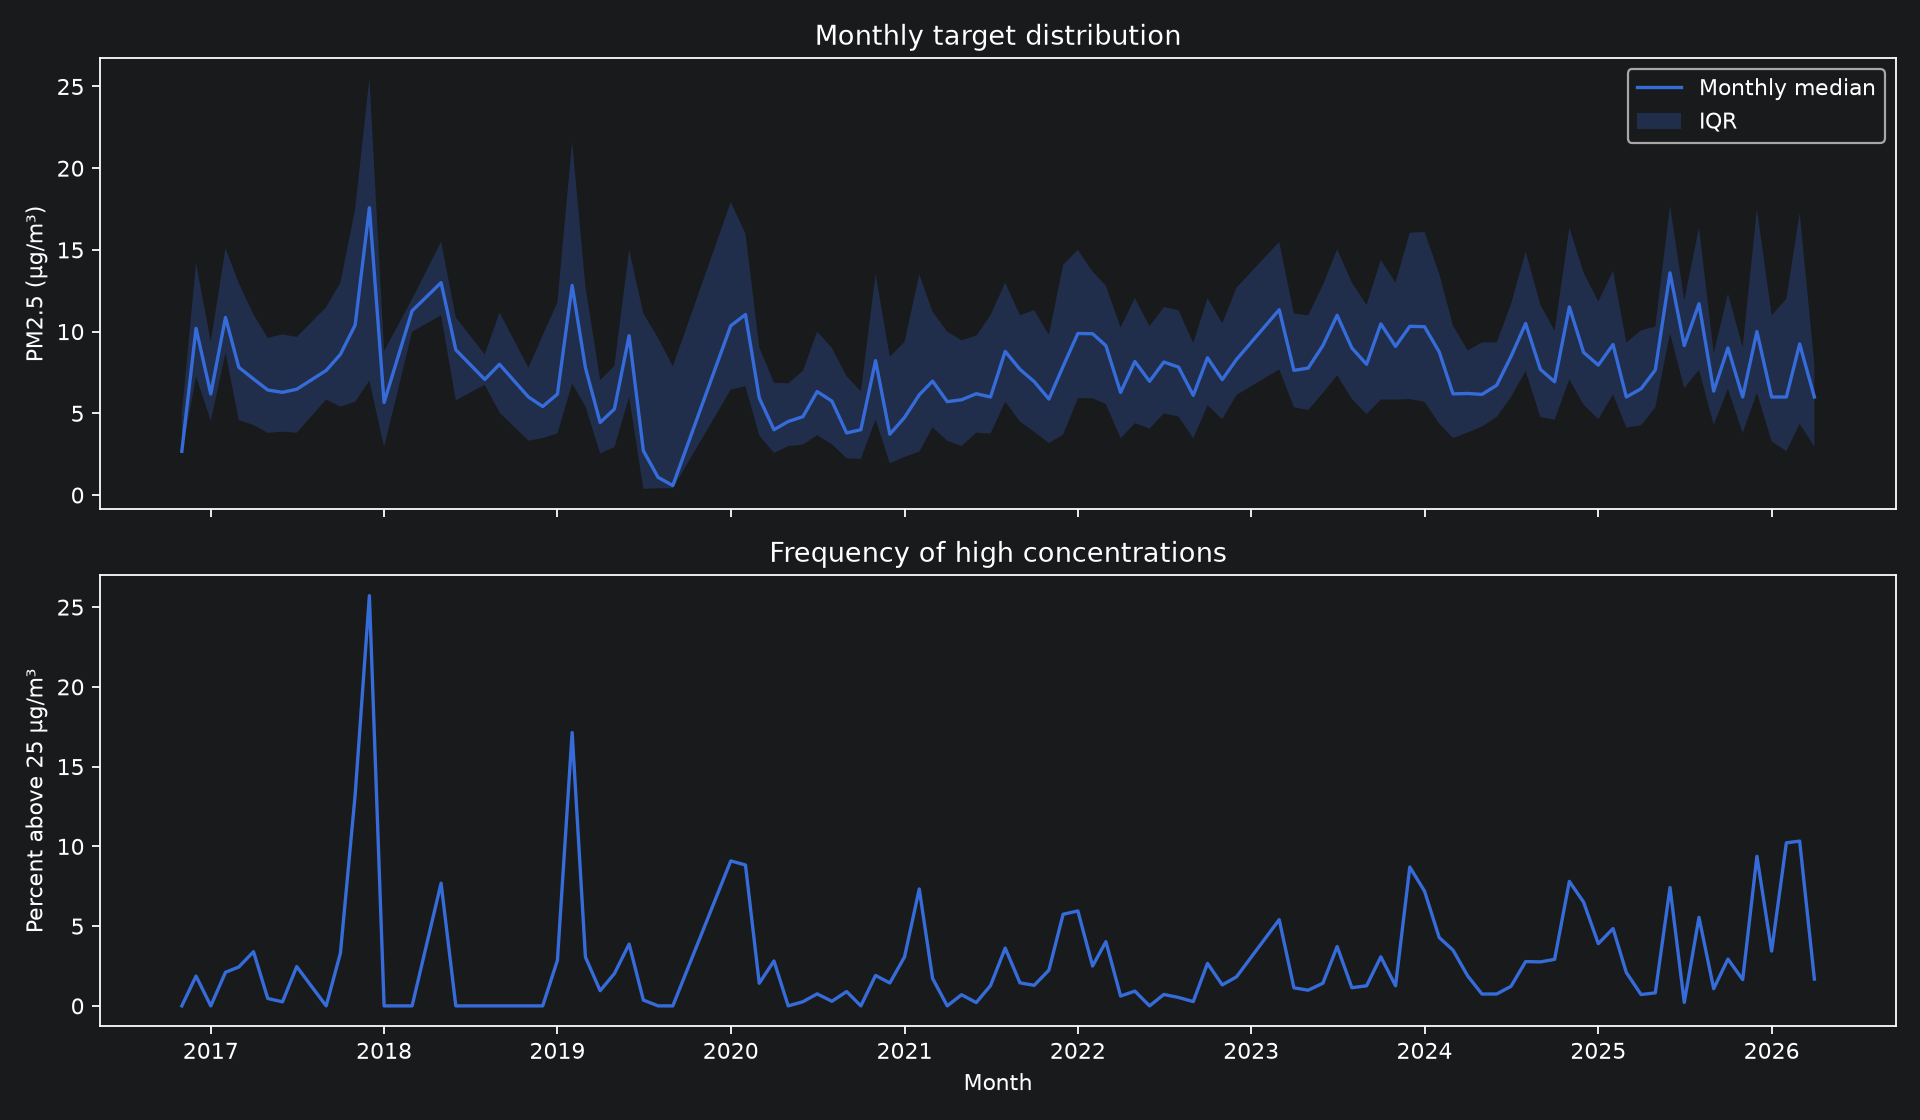

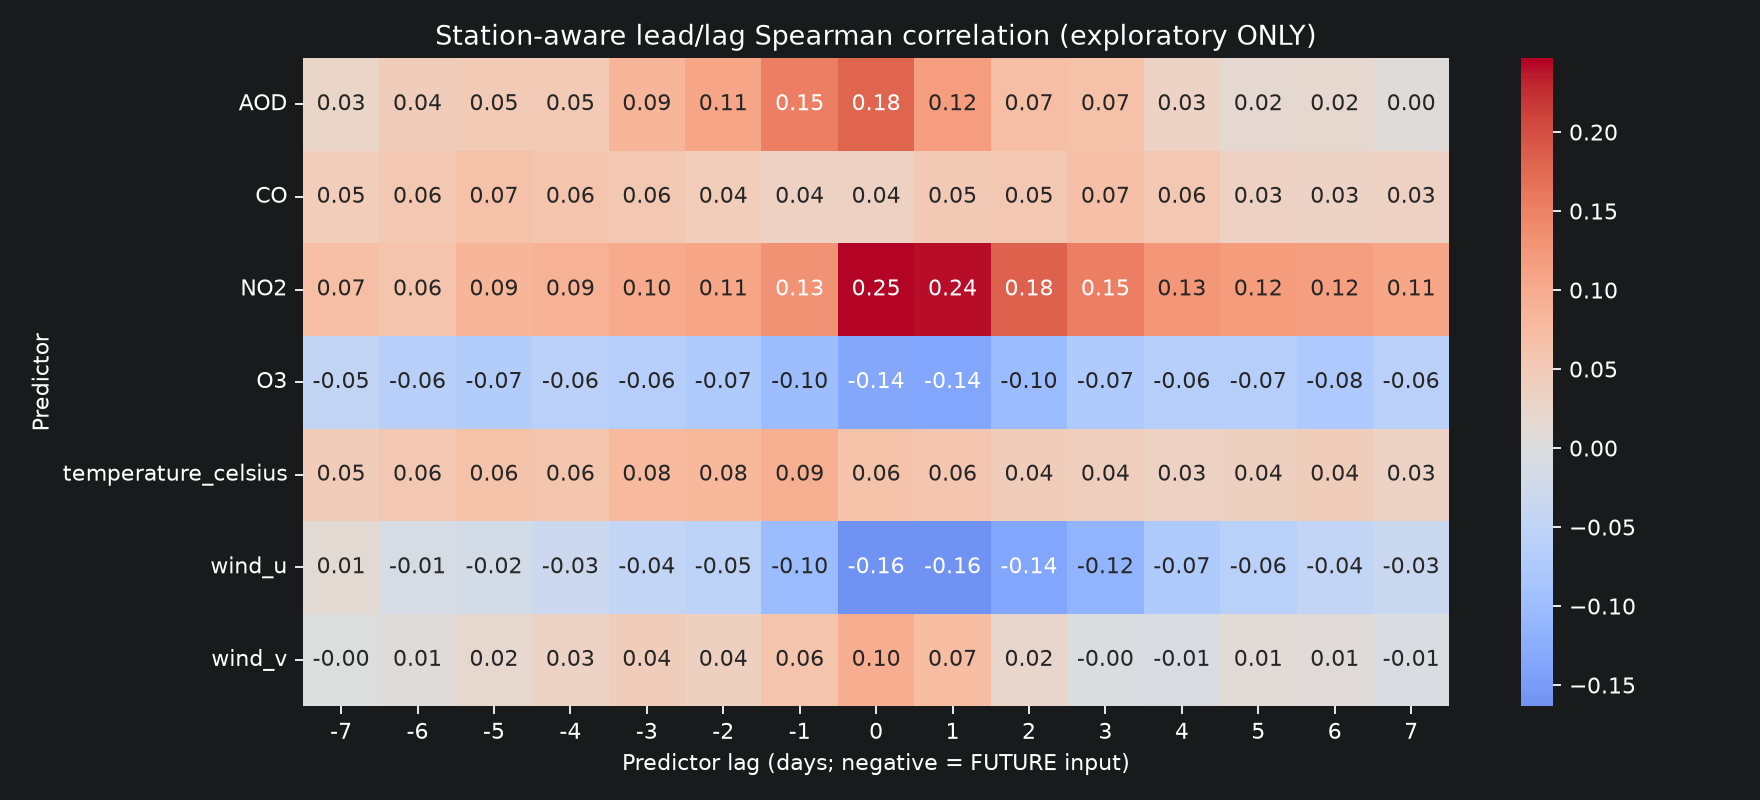

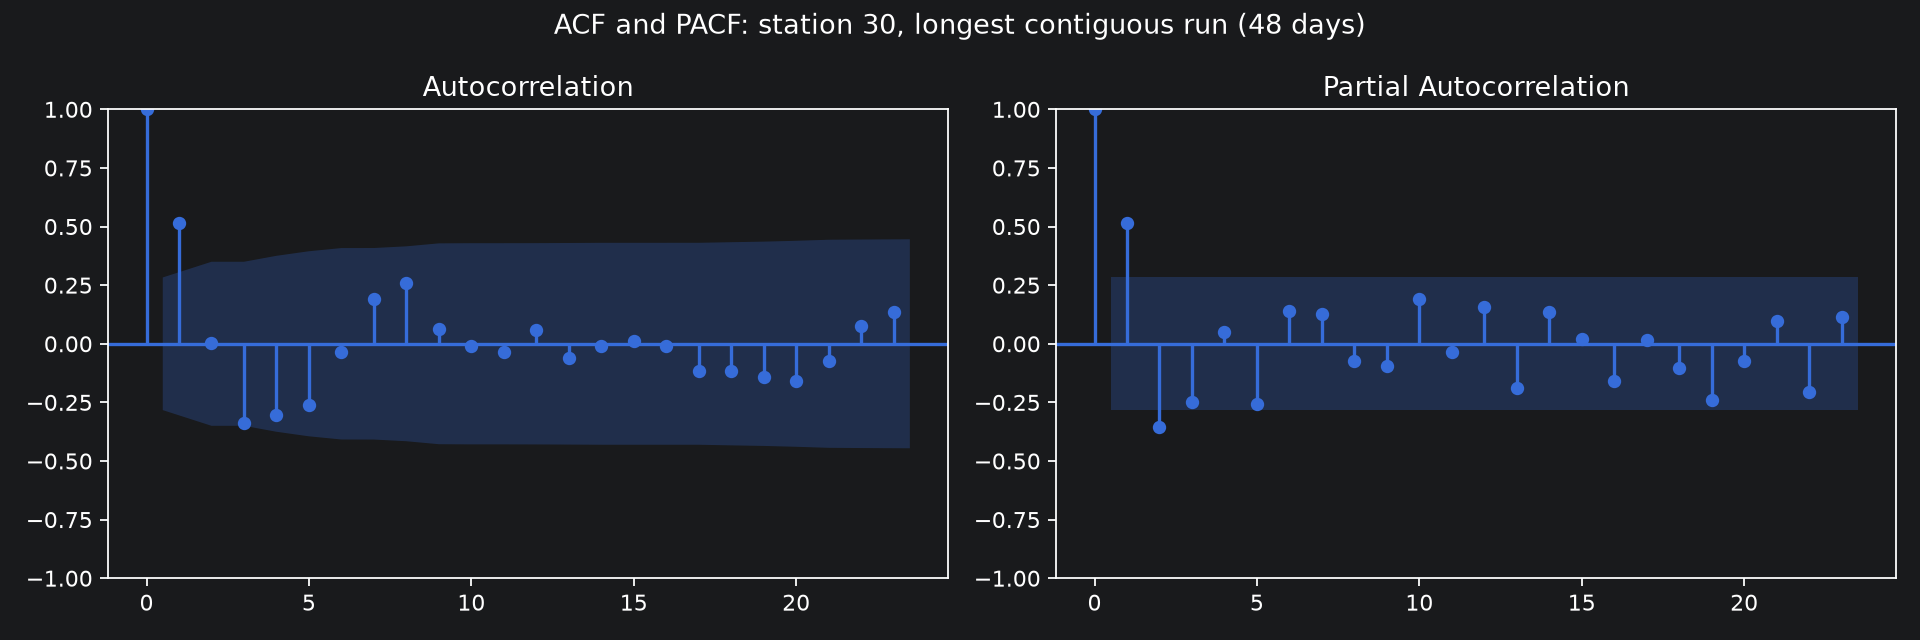

In [7]:
temporal_figures(clean,diagnostics,lags)
from src.timeseries import TEMPORAL_COLUMNS
diagnostics.reindex(columns=TEMPORAL_COLUMNS).to_csv(RESULTS_DIR/"Exploratory_temporal.csv",index=False)
print("Saved", RESULTS_DIR/"Exploratory_temporal.csv")
for chart in ("monthly_target_drift.png","lead_lag_heatmap.png","acf_pacf_longest_run.png"):
    display(Image(filename=str(FIGURES_DIR/"timeseries"/chart),width=700))

## Decision gate: proper forecasting

In [8]:
from src.features import make_development_and_test
from src.splits import create_folds
dev, future_test, info = make_development_and_test(clean)
print("Development pairs:", len(dev), "Future test pairs:",len(future_test))
print("Stations selected from development only:",info["eligible_stations_based_on_development_only"])
print("Run `python -m scripts.run_eda` to save fold JSON files without using the test period.")

Development pairs: 20012 Future test pairs: 3812
Stations selected from development only: 63
Run `python -m scripts.run_eda` to save fold JSON files without using the test period.
